# Choosing the number of clusters from correlations

The correlation distance turns similar return histories into nearby points and perfectly opposite histories into maximally separated points:

$$
d_{ij}=\sqrt{\frac{1-\rho_{ij}}{2}},
\qquad
0\leq d_{ij}\leq1.
$$

Here, $\rho_{ij}\in[-1,1]$ is the sample correlation between industries $i$ and $j$; $d_{ij}$ is their transformed distance. $i,j$ label industries; the divisor $2$ maps the full correlation range to squared distances from zero to one.

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display


def compact_float_format(number_format=None):
    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value


def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch(r"[+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?", rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return "0"
    if ("." in rendered or "e" in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered


def compact_numeric_text(text):
    pattern = r"(?<![0-9.eE])([+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])"
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)


def compact_table_latex(latex):
    return compact_numeric_text(latex)


def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + "</div>"


def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)

from pathlib import Path
import sys
import warnings
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, adjusted_rand_score, silhouette_samples
from sklearn.utils import check_random_state

ROOT = Path.cwd().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from book_support import ensure_dataset
import hashlib
import io
import zipfile

DATA_URL = "https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/49_Industry_Portfolios_daily_CSV.zip"
DATA_DIR = ROOT / "data" / "public" / "ken_french"
DATA_PATH = ensure_dataset(ROOT, "french_49_industries")
EXPECTED_DATA_HASH = "8F394FE34BEA54D41B9AAFED410425EE8F8E252EDE3C71A7C1CD20BAB83040DE"
DATA_DIR.mkdir(parents=True, exist_ok=True)
assert DATA_PATH.is_file()
data_hash = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest().upper()
assert data_hash == EXPECTED_DATA_HASH
with zipfile.ZipFile(DATA_PATH) as archive:
    archive_name = archive.namelist()[0]
    public_lines = archive.read(archive_name).decode("latin1").splitlines()
header_row = next(index for index, line in enumerate(public_lines) if line.startswith(",Agric"))
end_row = next(index for index in range(header_row + 1, len(public_lines)) if not public_lines[index].strip())
raw = pd.read_csv(io.StringIO("\n".join(public_lines[header_row:end_row])))
raw = raw.rename(columns={raw.columns[0]: "Date"})
raw["Date"] = pd.to_datetime(raw["Date"].astype(str), format="%Y%m%d")
raw = raw.set_index("Date").replace([-99.99, -999.0], np.nan) / 100.0
industry_returns = raw.loc["2019-01-01":"2025-12-31"].dropna().copy()

from RiskLabAI.cluster.clustering import cluster_k_means_base, cluster_k_means_top, random_block_correlation
from RiskLabAI.ensemble.bagging_classifier_accuracy import bagging_classifier_accuracy
from RiskLabAI.ensemble.empirical_bagging_accuracy import BaggingClassifierAccuracy, calculate_bootstrap_accuracy

warnings.filterwarnings("ignore", message="X has feature names")

FIGURES = ROOT / "outputs" / "figures" / "15_predictor_clustering"
TABLES = ROOT / "outputs" / "tables" / "15_predictor_clustering"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

selected_features = ["Food", "Beer", "Hshld", "Oil", "Coal", "Mines", "Hardw", "Softw", "Chips", "Banks", "Insur", "Fin"]
trailing_returns = industry_returns[selected_features].rolling(5).sum().shift(1)
market_direction = (industry_returns.mean(axis=1) > 0).astype(int).rename("Market direction")
public_frame = pd.concat([trailing_returns, market_direction], axis=1).dropna()
public_x = public_frame[selected_features]
public_y = public_frame["Market direction"]
split_index = int(len(public_x) * 0.70)
public_x_train = public_x.iloc[:split_index]
public_y_train = public_y.iloc[:split_index]
public_x_test = public_x.iloc[split_index:]
public_y_test = public_y.iloc[split_index:]

palette = {"background": "#FFFFFF", "axes": "#FFFFFF", "text": "#1B365D", "cyan": "#0072B2", "amber": "#C76D00", "green": "#00866A", "rose": "#B83B3B", "violet": "#A03A78", "grid": "#D9DEE5"}
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": palette["background"], "axes.facecolor": palette["axes"], "axes.edgecolor": palette["text"], "axes.labelcolor": palette["text"], "axes.titlecolor": palette["text"], "xtick.color": palette["text"], "ytick.color": palette["text"], "text.color": palette["text"], "grid.color": palette["grid"], "grid.linestyle": ":", "legend.facecolor": palette["axes"], "legend.edgecolor": palette["grid"], "savefig.facecolor": palette["background"]})

def save_table(frame, stem, caption, label, float_format="%.6f", fit=True):
    frame.to_csv(TABLES / f"{stem}.csv", index=False)
    latex = compact_table_latex(frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position="H"))
    if fit:
        latex = latex.replace(r"\begin{tabular}", r"\begin{adjustbox}{max width=\textwidth}\begin{tabular}", 1).replace(r"\end{tabular}", r"\end{tabular}\end{adjustbox}", 1)
    else:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{tabular}", 1)
    (TABLES / f"{stem}.tex").write_text(latex, encoding="utf-8")

def save_cluster_table(frame, stem, caption, label):
    frame.to_csv(TABLES / f"{stem}.csv", index=False)
    summary_columns = [column for column in frame.columns if column != "Industries"]
    headings = {
        "Cluster": "Cluster",
        "Size": "Size",
        "Mean silhouette": r"Mean $s$",
        "Minimum silhouette": r"Minimum $s$",
        "Quality": "Quality",
        "Mean within correlation": r"Mean $\rho$",
        "Mean within-cluster co-membership": "Mean joining frequency",
    }
    lines = [
        r"\begin{table}[H]",
        f"\\caption{{{caption}}}",
        f"\\label{{{label}}}",
        r"\centering",
        r"\small",
        r"\begin{tabular}{@{}" + "r" * len(summary_columns) + r"@{}}",
        r"\toprule",
        " & ".join(headings[column] for column in summary_columns) + r" \\",
        r"\midrule",
    ]
    for _, row in frame.iterrows():
        values = []
        for column in summary_columns:
            value = row[column]
            if column in {"Cluster", "Size"}:
                values.append(str(int(value)))
            else:
                values.append(f"{float(value):.6f}")
        lines.append(" & ".join(values) + r" \\")
    lines.extend([
        r"\bottomrule",
        r"\end{tabular}",
        r"\par\medskip",
        r"\begin{tabular}{@{}r p{0.82\textwidth}@{}}",
        r"\toprule",
        r"Cluster & Industries \\",
        r"\midrule",
    ])
    for _, row in frame.iterrows():
        members = str(row["Industries"]).replace("&", r"\&")
        lines.append(f"{int(row['Cluster'])} & {members}" + r" \\")
    lines.extend([r"\bottomrule", r"\end{tabular}", r"\end{table}"])
    (TABLES / f"{stem}.tex").write_text("\n".join(lines), encoding="utf-8")

def labels_from_clusters(columns, clusters):
    labels = pd.Series(index=columns, dtype="int64")
    for cluster_id, members in clusters.items():
        labels.loc[members] = int(cluster_id)
    return labels.astype(int)

def mean_within_correlation(correlation, members):
    if len(members) < 2:
        return 1.0
    block = correlation.loc[members, members].to_numpy()
    return block[np.triu_indices(len(members), 1)].mean()
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": "#FFFFFF", "axes.facecolor": "#FFFFFF", "axes.edgecolor": "#5C6670", "axes.labelcolor": "#1B365D", "axes.titlecolor": "#1B365D", "axes.titleweight": "bold", "xtick.color": "#5C6670", "ytick.color": "#5C6670", "text.color": "#1B365D", "grid.color": "#D9DEE5", "grid.linestyle": ":", "grid.linewidth": 0.8, "legend.facecolor": "#FFFFFF", "legend.edgecolor": "#D9DEE5", "legend.framealpha": 0.96, "savefig.facecolor": "#FFFFFF", "savefig.transparent": False, "savefig.dpi": 300, "pdf.fonttype": 42, "ps.fonttype": 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == "3.2.0"


## Public Industry Correlations

In [2]:
public_correlation = industry_returns.corr()
public_distance = np.sqrt((1 - public_correlation.fillna(0)) / 2.0)
correlation_summary = pd.DataFrame({
    "Quantity": ["Industries", "Daily observations", "Smallest off-diagonal correlation", "Median off-diagonal correlation", "Largest off-diagonal correlation", "Smallest distance", "Largest distance"],
    "Value": [public_correlation.shape[0], len(industry_returns), public_correlation.to_numpy()[np.triu_indices(49, 1)].min(), np.median(public_correlation.to_numpy()[np.triu_indices(49, 1)]), public_correlation.to_numpy()[np.triu_indices(49, 1)].max(), public_distance.to_numpy()[np.triu_indices(49, 1)].min(), public_distance.to_numpy()[np.triu_indices(49, 1)].max()],
})
save_table(correlation_summary, "correlation_summary", "Public industry correlation and distance summary.", "tab:chapter13-correlation-summary", fit=False)
display(correlation_summary)

,Quantity,Value
0,Industries,49
1,Daily observations,1760
2,Smallest off-diagonal correlation,0.139994
3,Median off-diagonal correlation,0.587965
4,Largest off-diagonal correlation,0.907867
5,Smallest distance,0.214631
6,Largest distance,0.655746


The silhouette compares an item's average distance inside its assigned cluster with its nearest alternative cluster:

$$
s_i=\frac{b_i-a_i}{\max(a_i,b_i)},
\qquad
a_i=\frac{1}{|C_i|-1}\sum_{j\in C_i,\,j\neq i}d_{ij},
\qquad
b_i=\min_{C\neq C_i}\frac{1}{|C|}\sum_{j\in C}d_{ij}.
$$

Here, $C_i$ is the cluster containing item $i$; $|C_i|$ is its size; $a_i$ is average within-cluster distance. $C$ is another cluster; $b_i$ is the smallest average distance to another cluster; $d_{ij}$ is correlation distance; $s_i\in[-1,1]$ is the silhouette.

## Selecting the Number of Clusters

The released search favors a clustering whose silhouettes have a large positive mean relative to their spread:

$$
q(k,r)=\frac{\overline s(k,r)}{\operatorname{sd}\{s_i(k,r)\}},
\qquad
(\widehat k,\widehat r)=\arg\max_{2\leq k\leq K,\,1\leq r\leq R}q(k,r).
$$

Here, $k$ is the candidate cluster count; $r$ is a repeated starting state; $s_i(k,r)$ is item $i$'s silhouette. $\overline s$ is mean silhouette; $\operatorname{sd}$ is its population standard deviation; $q$ is search quality; $K=12$ and $R=20$ here; $\widehat k,\widehat r$ maximize $q.$

,Clusters,Best mean silhouette,Best silhouette standard deviation,Best quality,Best seed
0,2,0.312292,0.151151,2.066097,594000744
1,3,0.241911,0.131830,1.835027,358403712
2,4,0.212596,0.126377,1.682232,1452363051
3,5,0.143380,0.103080,1.390959,1981586709
4,6,0.160680,0.113327,1.417836,551805310
5,7,0.126303,0.092957,1.358720,1361484638
6,8,0.131348,0.096944,1.354888,488713542
7,9,0.129742,0.097681,1.328216,2122803701
8,10,0.131420,0.093664,1.403105,1966224751
9,11,0.123524,0.101385,1.218368,1160701416


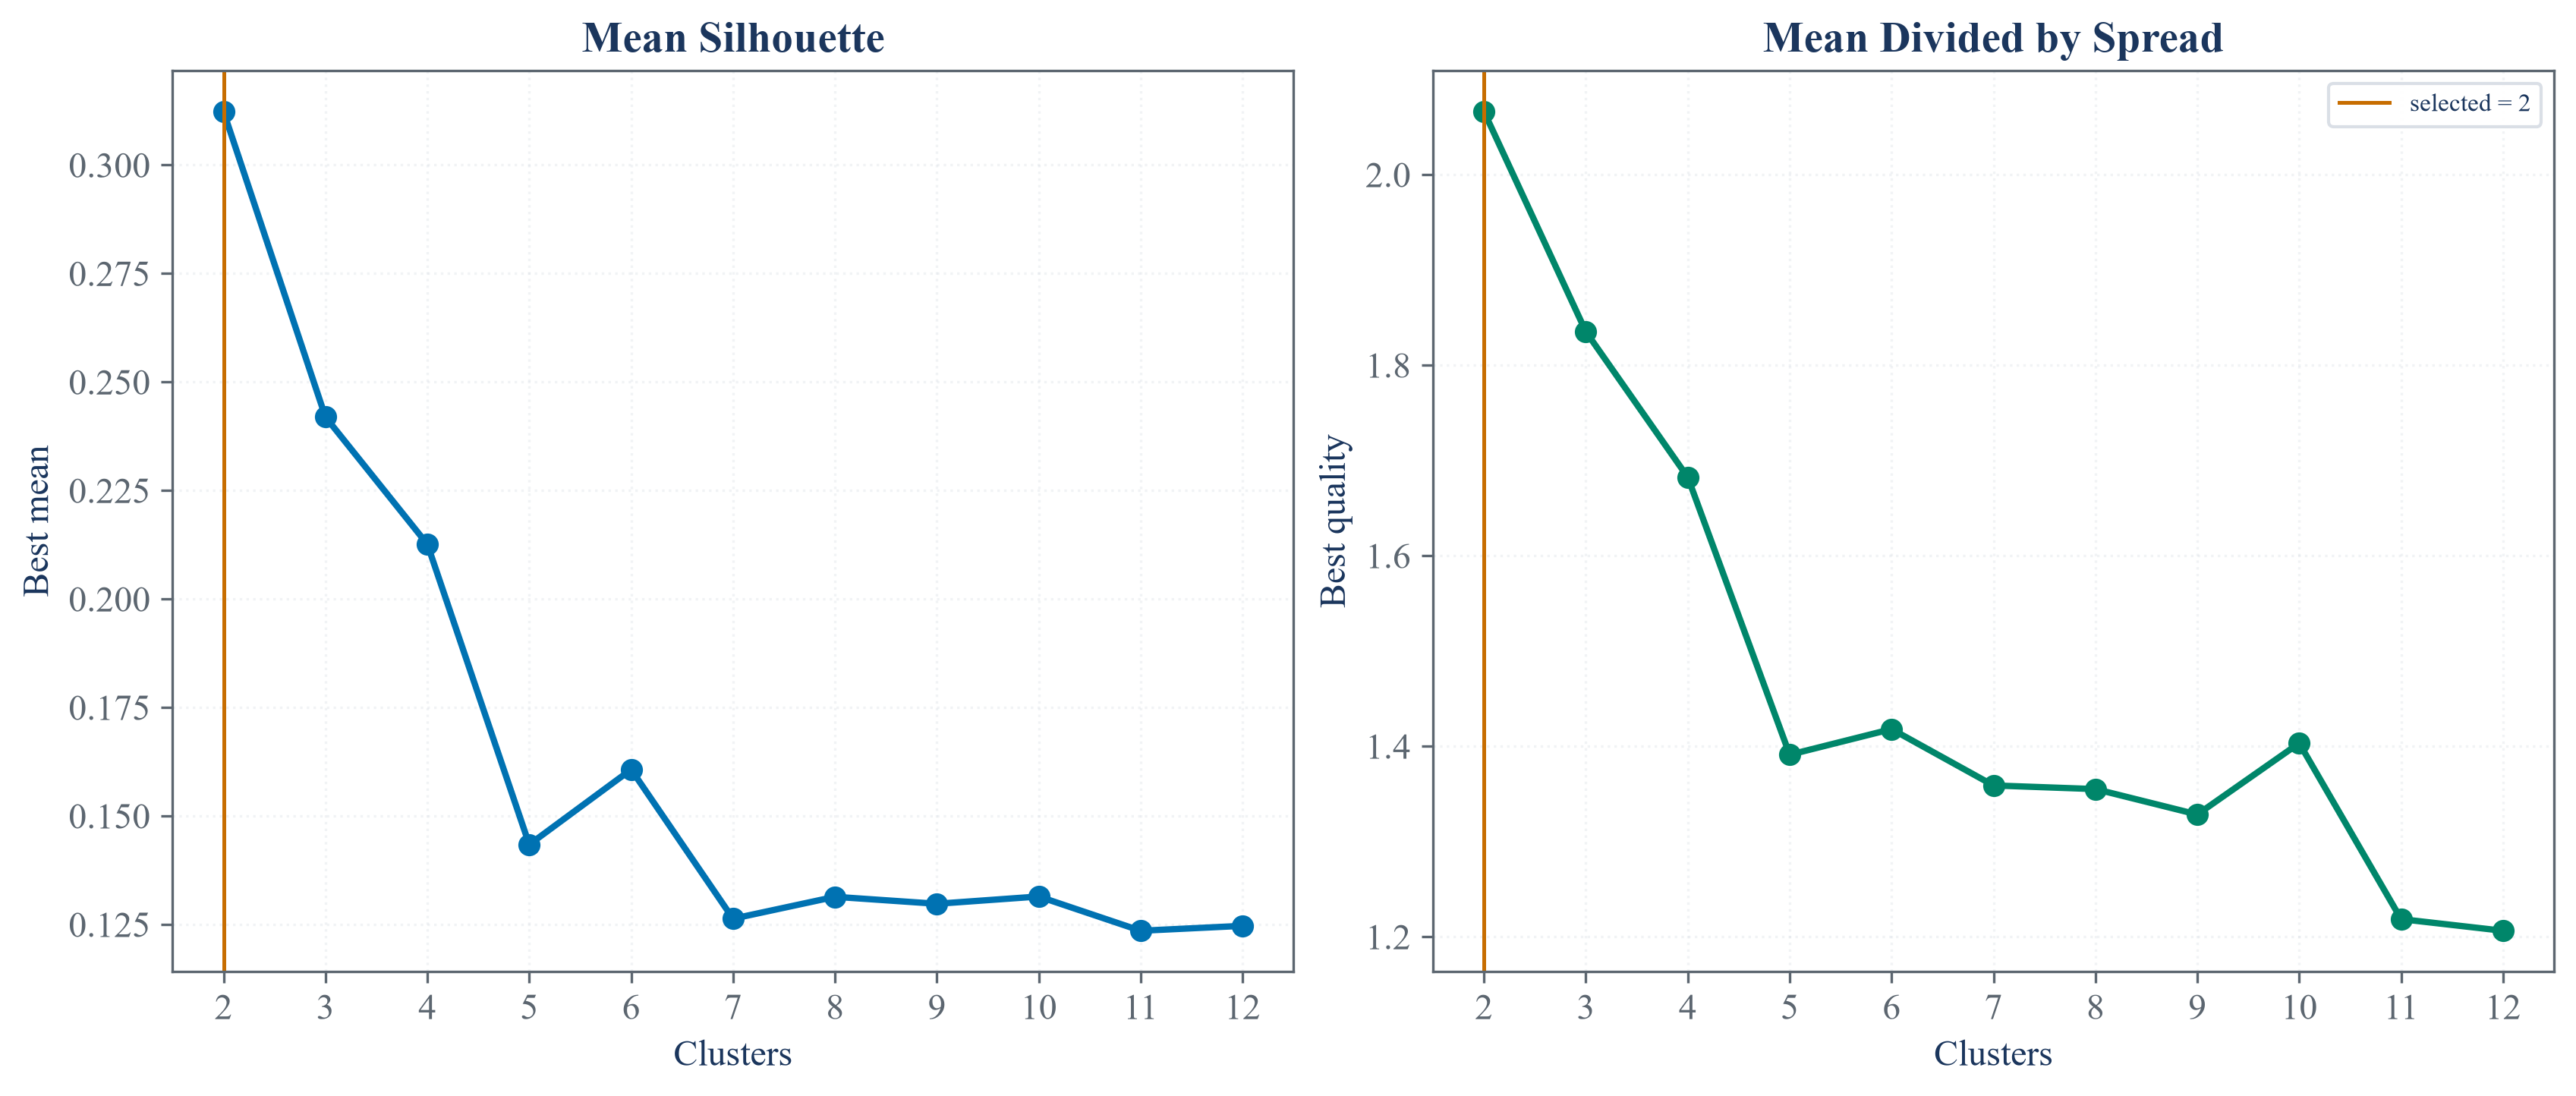

In [3]:
search_rng = check_random_state(13021)
search_rows = []
best_labels_by_count = {}
for repetition in range(20):
    for cluster_count in range(2, 13):
        current_seed = search_rng.randint(0, np.iinfo(np.int32).max)
        current_model = KMeans(n_clusters=cluster_count, n_init=1, random_state=current_seed)
        current_labels = current_model.fit_predict(public_distance)
        current_silhouette = silhouette_samples(public_distance, current_labels)
        current_quality = current_silhouette.mean() / current_silhouette.std()
        search_rows.append({"Clusters": cluster_count, "Repetition": repetition + 1, "Mean silhouette": current_silhouette.mean(), "Silhouette standard deviation": current_silhouette.std(), "Quality": current_quality, "Seed": current_seed})
        previous = best_labels_by_count.get(cluster_count)
        if previous is None or current_quality > previous[0]:
            best_labels_by_count[cluster_count] = (current_quality, current_labels.copy(), current_silhouette.copy(), current_seed)
cluster_search_paths = pd.DataFrame(search_rows)
cluster_quality = pd.DataFrame([
    {"Clusters": cluster_count, "Best mean silhouette": best_labels_by_count[cluster_count][2].mean(), "Best silhouette standard deviation": best_labels_by_count[cluster_count][2].std(), "Best quality": best_labels_by_count[cluster_count][0], "Best seed": best_labels_by_count[cluster_count][3]}
    for cluster_count in range(2, 13)
])
selected_count = int(cluster_quality.loc[cluster_quality["Best quality"].idxmax(), "Clusters"])
base_sorted, base_clusters, base_silhouette = cluster_k_means_base(public_correlation, max_clusters=12, iterations=20, random_state=13021)
base_labels = labels_from_clusters(public_correlation.columns, base_clusters)
independently_selected_labels = pd.Series(best_labels_by_count[selected_count][1], index=public_correlation.columns)
save_table(cluster_quality, "cluster_quality", "Best public silhouette quality for each candidate cluster count.", "tab:chapter13-cluster-quality", fit=True)
display(cluster_quality.round(6))

figure, axes = plt.subplots(1, 2, figsize=(11.2, 4.7), constrained_layout=True)
axes[0].plot(cluster_quality["Clusters"], cluster_quality["Best mean silhouette"], color=palette["cyan"], marker="o", linewidth=2.0)
axes[0].axvline(selected_count, color=palette["amber"], linewidth=1.2)
axes[0].set_title("Mean Silhouette")
axes[0].set_xlabel("Clusters")
axes[0].set_ylabel("Best mean")
axes[1].plot(cluster_quality["Clusters"], cluster_quality["Best quality"], color=palette["green"], marker="o", linewidth=2.0)
axes[1].axvline(selected_count, color=palette["amber"], linewidth=1.2, label=f"selected = {selected_count}")
axes[1].set_title("Mean Divided by Spread")
axes[1].set_xlabel("Clusters")
axes[1].set_ylabel("Best quality")
axes[1].legend(fontsize=8)
for axis in axes:
    axis.set_xticks(range(2, 13))
    axis.grid(alpha=0.35)
figure.savefig(FIGURES / "public_cluster_quality.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "public_cluster_quality.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "public_cluster_quality.png")))
plt.close(figure)

## Base Clustering Result

,Cluster,Size,Mean silhouette,Minimum silhouette,Mean within correlation,Industries
0,1,44,0.330776,0.046216,0.619203,"Agric, Food, Soda, Beer, Toys, Fun, Books, Hsh..."
1,2,5,0.149627,-0.020821,0.236933,"Smoke, Autos, Guns, Gold, Coal"


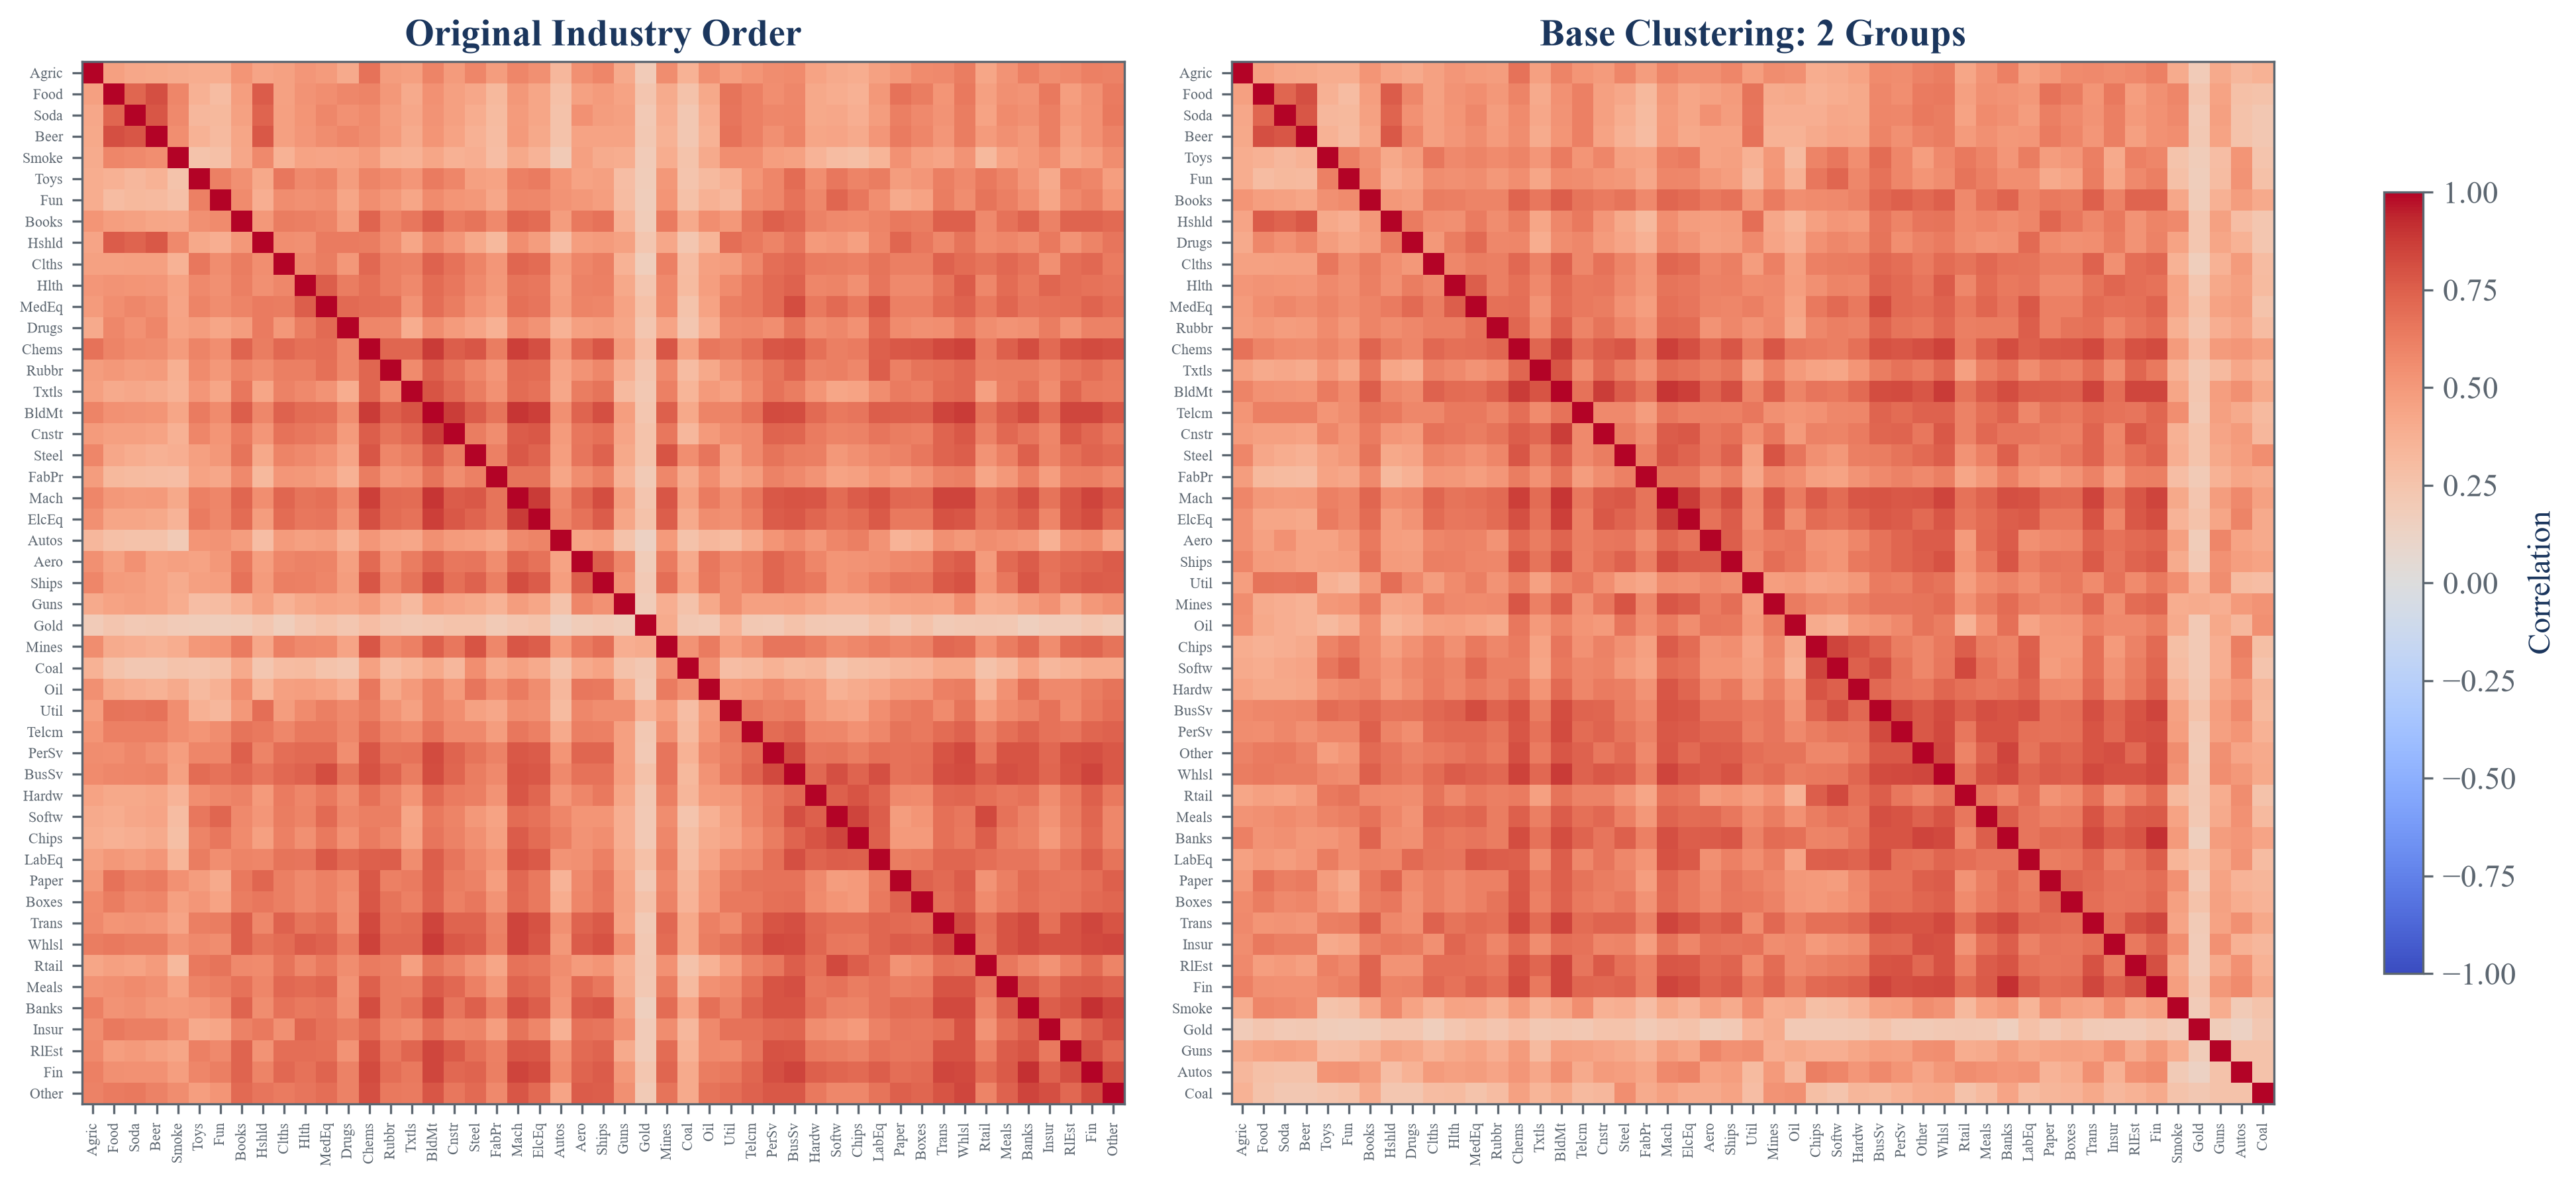

In [4]:
base_cluster_rows = []
for cluster_id, members in base_clusters.items():
    base_cluster_rows.append({"Cluster": int(cluster_id) + 1, "Size": len(members), "Mean silhouette": base_silhouette.loc[members].mean(), "Minimum silhouette": base_silhouette.loc[members].min(), "Mean within correlation": mean_within_correlation(public_correlation, members), "Industries": ", ".join(members)})
base_cluster_summary = pd.DataFrame(base_cluster_rows).sort_values("Cluster")
save_cluster_table(base_cluster_summary, "base_cluster_summary", "Base public clusters chosen by the released search.", "tab:chapter13-base-cluster-summary")
display(base_cluster_summary.round(6))

figure, axes = plt.subplots(1, 2, figsize=(13.0, 5.8), constrained_layout=True)
images = []
for axis, matrix, title in [(axes[0], public_correlation, "Original Industry Order"), (axes[1], base_sorted, f"Base Clustering: {len(base_clusters)} Groups")]:
    current_image = axis.imshow(matrix.to_numpy(), cmap="coolwarm", vmin=-1.0, vmax=1.0)
    images.append(current_image)
    axis.set_title(title)
    axis.set_xticks(np.arange(49), matrix.columns, rotation=90, fontsize=5.2)
    axis.set_yticks(np.arange(49), matrix.index, fontsize=5.2)
figure.colorbar(images[-1], ax=axes, shrink=0.75, label="Correlation")
figure.savefig(FIGURES / "public_base_clusters.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "public_base_clusters.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "public_base_clusters.png")))
plt.close(figure)

## Tests

In [5]:
assert data_hash == EXPECTED_DATA_HASH
assert industry_returns.shape == (1760, 49)
assert public_correlation.shape == (49, 49)
assert public_distance.shape == (49, 49)
assert np.allclose(np.diag(public_correlation), 1.0)
assert np.allclose(np.diag(public_distance), 0.0)
assert np.allclose(public_correlation, public_correlation.T)
assert np.allclose(public_distance, public_distance.T)
assert public_distance.to_numpy().min() >= 0
assert public_distance.to_numpy().max() <= 1
assert correlation_summary.shape == (7, 2)
assert cluster_search_paths.shape == (220, 6)
assert cluster_quality.shape == (11, 5)
assert cluster_quality["Clusters"].tolist() == list(range(2, 13))
assert 2 <= selected_count <= 12
assert len(base_clusters) == selected_count
assert set(item for members in base_clusters.values() for item in members) == set(public_correlation.columns)
assert sum(len(members) for members in base_clusters.values()) == 49
assert base_sorted.shape == (49, 49)
assert base_silhouette.shape == (49,)
assert base_silhouette.between(-1, 1).all()
assert np.array_equal(base_labels.to_numpy(), independently_selected_labels.to_numpy())
assert np.isclose(base_silhouette.mean() / base_silhouette.to_numpy().std(), cluster_quality["Best quality"].max())
assert base_cluster_summary.shape == (selected_count, 6)
assert base_cluster_summary["Size"].sum() == 49
assert base_cluster_summary["Mean within correlation"].between(-1, 1).all()
assert (FIGURES / "public_cluster_quality.pdf").is_file()
assert (FIGURES / "public_base_clusters.pdf").is_file()
assert (TABLES / "correlation_summary.tex").is_file()
assert (TABLES / "cluster_quality.tex").is_file()
assert (TABLES / "base_cluster_summary.tex").is_file()